# Analyzing dbNSFP5.0 alleles with ClinVar

In [13]:
import os
import polars as pl
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
# import concurrent.futures

aa_single_to_three = {
    'A': 'Ala',  # Alanine
    'R': 'Arg',  # Arginine
    'N': 'Asn',  # Asparagine
    'D': 'Asp',  # Aspartic acid
    'C': 'Cys',  # Cysteine
    'Q': 'Gln',  # Glutamine
    'E': 'Glu',  # Glutamic acid
    'G': 'Gly',  # Glycine
    'H': 'His',  # Histidine
    'I': 'Ile',  # Isoleucine
    'L': 'Leu',  # Leucine
    'K': 'Lys',  # Lysine
    'M': 'Met',  # Methionine
    'F': 'Phe',  # Phenylalanine
    'P': 'Pro',  # Proline
    'S': 'Ser',  # Serine
    'T': 'Thr',  # Threonine
    'W': 'Trp',  # Tryptophan
    'Y': 'Tyr',  # Tyrosine
    'V': 'Val'   # Valine
}

## Get the prediction scores and clean ClinVar annotation

In [ ]:
# chr_num_list = [chr_file.split('.')[-2].split('chr')[-1] for chr_file in os.listdir('../1_inputs/raw_data/dbNSFP5.0a/') if "chr" in chr_file and chr_file.endswith(".gz")]
# clin_var_dfs = []
# for chr_num in chr_num_list:
#     df_chr_par = pl.scan_parquet(f"../1_inputs/raw_data/dbNSFP5.0a/dbNSFP5.0a_variant.chr{chr_num}.parquet")
#     df_chr_par_clinvar = df_chr_par.filter(pl.col("clinvar_id")!='.')
#     df_chr_par_clinvar = df_chr_par_clinvar.collect()
#     clin_var_dfs.append(df_chr_par_clinvar)
# df_clinvar = pl.concat(clin_var_dfs, how="vertical_relaxed")

In [3]:
# ## Create the mapping expression with precise logic for a cleaner ClinVar Annotation
# clinvar_mapping = (
#     # First check for Conflicting interpretations (highest priority)
#     pl.when(
#         pl.col("clinvar_clnsig").str.to_lowercase().str.contains("conflicting")
#     )
#     .then(pl.lit("3_Conflicting"))
#     # Then check for Uncertain significance (VUS)
#     .when(pl.col("clinvar_clnsig").str.to_lowercase().str.contains("uncertain"))
#     .then(pl.lit("4_VUS"))
#     # # Special case for strings containing both "Uncertain significance" and "Pathogenic"
#     # .when(
#     #     pl.col("clinvar_clnsig").str.to_lowercase().str.contains("uncertain") &
#     #     pl.col("clinvar_clnsig").str.to_lowercase().str.contains("pathogenic")
#     # )
#     # .then(pl.lit("4_VUS"))  # The dictionary says to classify this as VUS
#     # Check for Pathogenic
#     .when(pl.col("clinvar_clnsig").str.to_lowercase().str.contains("pathogenic"))
#     .then(pl.lit("1_Pathogenic"))
#     # Check for Benign
#     .when(pl.col("clinvar_clnsig").str.to_lowercase().str.contains("benign"))
#     .then(pl.lit("2_Benign"))
#     # Everything else goes to Others
#     .otherwise(pl.lit("5_Others"))
# )

# # Apply the mapping to create a new column
# df_clinvar = df_clinvar.with_columns(clinvar_clnsig_clean=clinvar_mapping)

# # Create a dataframe with unique mappings to check accuracy
# unique_mappings = df_clinvar.select(
#     pl.col("clinvar_clnsig"),
#     pl.col("clinvar_clnsig_clean")
# ).unique()

# # Sort by original value for easier verification
# unique_mappings = unique_mappings.sort("clinvar_clnsig")

# # Print each mapping to verify accuracy
# print("Original Value -> Mapped Value")
# print("-" * 50)
# for row in unique_mappings.rows():
#     print(f"{row[0]} -> {row[1]}")

In [ ]:
# parquet_path = f"../1_inputs/raw_inputs/dbNSFP5.0a/dbNSFP5.0a_variant.clin_var_annot.parquet"
# df_clinvar.write_parquet(parquet_path)

## Preprocess the ClinVar Annotation

In [ ]:
df_clinvar = pl.scan_parquet(f"../3_outputs/processed_data/dbnsfp/dbNSFP5.0a_variant.clin_var_re-annot_dedup_variants.parquet")
# df_clinvar.collect()
# df_clinvar.filter(pl.col("aaalt").str.len_chars() == 1).collect()

In [14]:
# Once you’re happy with the behavior on the subset,
# you can apply it to the entire lazy DataFrame.
# Assume ldf is your lazy DataFrame.
# Randomly sample 1000 rows from the exploded DataFrame
# df_clinvar_sampled = df_clinvar_exploded.collect().sample(n=1000)

variant_annot = [
    "hg19_chr","genename","Ensembl_geneid","Ensembl_proteinid",
    "Uniprot_acc","Uniprot_entry",
    "aapos","aaref","aaref_3","aaalt","aaalt_3",#"aa_change",
    "Ensembl_transcriptid","hg19_pos(1-based)","HGVSc_snpEff","HGVSp_snpEff",
    "HGVSc_VEP","HGVSp_VEP",
]
predictor_algos = [
    "PROVEAN_score","PROVEAN_converted_rankscore","PROVEAN_pred",
    "ESM1b_score","ESM1b_rankscore","ESM1b_pred",
    "AlphaMissense_score","AlphaMissense_rankscore","AlphaMissense_pred"
] + [col for col in df_clinvar.collect_schema().names() if "clinvar" in col]

In [16]:
df_clinvar_sampled_plots = df_clinvar.select(
    pl.col("ESM1b_score","AlphaMissense_score","PROVEAN_score","clinvar_clnsig_clean")
).with_columns(
    pl.col("ESM1b_score").replace(".", None).cast(pl.Float64).alias("esm1b"),
    pl.col("AlphaMissense_score").replace(".", None).cast(pl.Float64).alias("alphamissense"),
    pl.col("PROVEAN_score").replace(".", None).cast(pl.Float64).alias("provean")
).filter((pl.col("clinvar_clnsig_clean")!="4_VUS")&(pl.col("clinvar_clnsig_clean")!="5_Others")).collect()

# Define variables to plot
variables = ["esm1b", "alphamissense", "provean"]

# Create a FacetGrid for multiple subplots
fig, axes = plt.subplots(1, 3, figsize=(15, 5)) ## , sharey=True
hue_order = sorted(df_clinvar_sampled_plots["clinvar_clnsig_clean"].drop_nulls().unique().to_list())
# Loop through variables and create subplots
for ax, var in zip(axes, variables):
    sns.kdeplot(
        data=df_clinvar_sampled_plots,
        x=var,
        hue="clinvar_clnsig_clean",
        hue_order=hue_order,
        # kde=True,
        ax=ax
    )
    ax.set_title(var)
    
plt.tight_layout()
plt.show()

InvalidOperationError: conversion from `str` to `f64` failed in column 'ESM1b_score' for 9217 out of 12218 values: [".;0.123;0.137;.", "-9.185;.;.", … "-3.095;-3.085"]

Columns containing ';': ['aapos', 'genename', 'Ensembl_geneid', 'Ensembl_transcriptid', 'Ensembl_proteinid', 'Uniprot_acc', 'Uniprot_entry', 'HGVSc_snpEff', 'HGVSp_snpEff', 'HGVSc_VEP', 'HGVSp_VEP', 'APPRIS', 'GENCODE_basic', 'TSL', 'VEP_canonical', 'MANE', 'cds_strand', 'refcodon', 'codonpos', 'codon_degeneracy', 'SIFT_score', 'SIFT_pred', 'SIFT4G_score', 'SIFT4G_pred', 'Polyphen2_HDIV_score', 'Polyphen2_HDIV_pred', 'Polyphen2_HVAR_score', 'Polyphen2_HVAR_pred', 'MutationTaster_score', 'MutationTaster_pred', 'MutationTaster_model', 'MutationTaster_trees_benign', 'MutationTaster_trees_deleterious', 'MutationAssessor_score', 'MutationAssessor_pred', 'PROVEAN_score', 'PROVEAN_pred', 'VEST4_score', 'MetaRNN_score', 'MetaRNN_pred', 'REVEL_score', 'MutPred_score', 'MutPred_protID', 'MutPred_AAchange', 'MutPred_Top5features', 'MVP_score', 'gMVP_score', 'MPC_score', 'DEOGEN2_score', 'DEOGEN2_pred', 'LIST-S2_score', 'LIST-S2_pred', 'VARITY_R_score', 'VARITY_ER_score', 'VARITY_R_LOO_score', 'VA

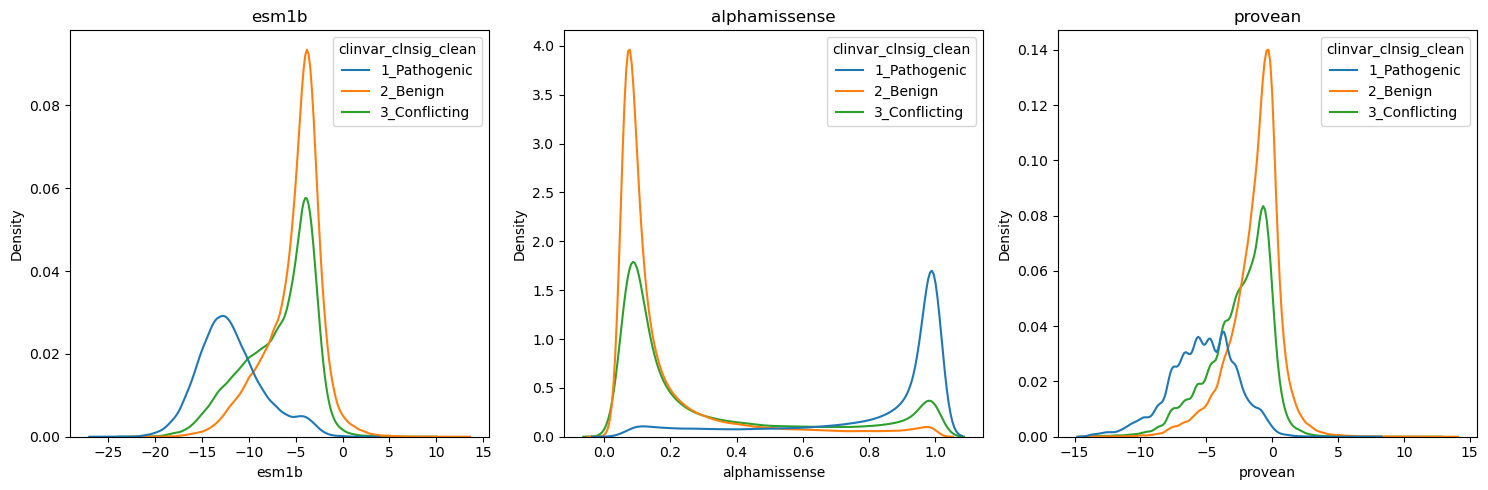

In [8]:
df_clinvar = pl.scan_parquet("../3_outputs/processed_data/dbnsfp/dbNSFP5.0a_variant.clin_var_re-annot.parquet")
# For testing purposes, limit to a small subset:
df_clin_subset = df_clinvar.limit(10)

# Collect the subset into an eager DataFrame for inspection
df_clin_subset = df_clin_subset.collect()

# Automatically detect columns with semicolon-separated patterns.
# We only check columns of Utf8 (string) type.
pattern_cols = [
    col for col in df_clinvar.collect_schema() 
    if df_clin_subset[col].dtype == pl.Utf8 and df_clin_subset[col].str.contains(";").any()
]
print("Columns containing ';':", pattern_cols)

df_clinvar_exploded = df_clinvar.with_columns(
    [pl.col(col).str.split(";").alias(col) for col in pattern_cols]
).explode(pattern_cols)

df_clinvar_sampled = df_clinvar_exploded.collect().unique(subset=["genename","HGVSp_snpEff"], keep="first")
df_clinvar_sampled_plots = df_clinvar_sampled.select(
    pl.col("ESM1b_score","AlphaMissense_score","PROVEAN_score","clinvar_clnsig_clean")
).with_columns(
    pl.col("ESM1b_score").replace(".", None).cast(pl.Float64).alias("esm1b"),
    pl.col("AlphaMissense_score").replace(".", None).cast(pl.Float64).alias("alphamissense"),
    pl.col("PROVEAN_score").replace(".", None).cast(pl.Float64).alias("provean")
).filter((pl.col("clinvar_clnsig_clean")!="4_VUS")&(pl.col("clinvar_clnsig_clean")!="5_Others"))

# Define variables to plot
variables = ["esm1b", "alphamissense", "provean"]

# Create a FacetGrid for multiple subplots
fig, axes = plt.subplots(1, 3, figsize=(15, 5)) ## , sharey=True
hue_order = sorted(df_clinvar_sampled_plots["clinvar_clnsig_clean"].drop_nulls().unique().to_list())
# Loop through variables and create subplots
for ax, var in zip(axes, variables):
    sns.kdeplot(
        data=df_clinvar_sampled_plots,
        x=var,
        hue="clinvar_clnsig_clean",
        hue_order=hue_order,
        # kde=True,
        ax=ax
    )
    ax.set_title(var)
    
plt.tight_layout()
plt.show()

In [11]:
df_clinvar.collect()

#chr,pos(1-based),ref,alt,aaref,aaalt,rs_dbSNP,hg19_chr,hg19_pos(1-based),hg18_chr,hg18_pos(1-based),aapos,genename,Ensembl_geneid,Ensembl_transcriptid,Ensembl_proteinid,Uniprot_acc,Uniprot_entry,HGVSc_snpEff,HGVSp_snpEff,HGVSc_VEP,HGVSp_VEP,APPRIS,GENCODE_basic,TSL,VEP_canonical,MANE,cds_strand,refcodon,codonpos,codon_degeneracy,Ancestral_allele,AltaiNeandertal,Denisova,VindijiaNeandertal,ChagyrskayaNeandertal,SIFT_score,…,nsv/esv (dbVar),RCVaccession,PhenotypeIDS,PhenotypeList,Origin,OriginSimple,Assembly,ChromosomeAccession,Chromosome,Start,Stop,Cytogenetic,ReviewStatus,NumberSubmitters,Guidelines,TestedInGTR,OtherIDs,SubmitterCategories,VariationID,PositionVCF,ReferenceAlleleVCF,AlternateAlleleVCF,SomaticClinicalImpact,SomaticClinicalImpactLastEvaluated,ReviewStatusClinicalImpact,Oncogenicity,OncogenicityLastEvaluated,ReviewStatusOncogenicity,SCVsForAggregateGermlineClassification,SCVsForAggregateSomaticClinicalImpact,SCVsForAggregateOncogenicityClassification,clinvar_nt_change,clinvar_aa_change,SPDI,RefSeq_mRNA,StarStatus,clinvar_clnsig_clean
str,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,…,str,str,str,str,str,str,cat,str,str,i64,i64,str,cat,i64,str,str,str,i64,i64,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i32,cat
"""21""",10541137,"""G""","""C""","""V""","""L""","""rs150733676""",""".""",""".""",""".""",""".""","""13;13;13;13""","""TPTE;TPTE;TPTE;TPTE""","""ENSG00000274391;ENSG0000027439…","""ENST00000622113;ENST0000061295…","""ENSP00000482040;ENSP0000048406…","""P56180-2;A0A087X1C4;P56180-3;P…","""TPTE_HUMAN;A0A087X1C4_HUMAN;TP…","""c.37G>C;c.37G>C;c.37G>C;c.37G>…","""p.Val13Leu;p.Val13Leu;p.Val13L…","""c.37G>C;c.37G>C;c.37G>C;c.37G>…","""p.Val13Leu;p.Val13Leu;p.Val13L…","""alternative2;.;alternative2;pr…","""Y;.;Y;Y""","""1;5;1;1""",""".;.;.;YES""",""".;.;.;Select""","""+;+;+;+""","""GTC;GTC;GTC;GTC""","""1;1;1;1""","""0;0;0;0""","""g""","""./.""","""./.""","""./.""","""./.""",""".;.;.;.""",…,"""-""","""RCV004175219""","""MedGen:CN169374""","""not specified""","""germline""","""germline""","""GRCh38""","""NC_000021.9""","""21""",10541137,10541137,"""21p11.2""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA9978559""",2,2333487,10541137,"""G""","""C""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV003666233""","""-""","""-""","""37G>C ""","""Val13Leu""","""NC_000021.9:10541137:G:C""","""NM_199261.4""",1,"""4_VUS"""
"""21""",10552695,"""C""","""G""","""A""","""G""","""rs766186396""",""".""",""".""",""".""",""".""","""53;53;71""","""TPTE;TPTE;TPTE""","""ENSG00000274391;ENSG0000027439…","""ENST00000622113;ENST0000061295…","""ENSP00000482040;ENSP0000048406…","""P56180-2;A0A087X1C4;P56180""","""TPTE_HUMAN;A0A087X1C4_HUMAN;TP…","""c.158C>G;c.158C>G;c.212C>G""","""p.Ala53Gly;p.Ala53Gly;p.Ala71G…","""c.158C>G;c.158C>G;c.212C>G""","""p.Ala53Gly;p.Ala53Gly;p.Ala71G…","""alternative2;.;principal4""","""Y;.;Y""","""1;5;1""",""".;.;YES""",""".;.;Select""","""+;+;+""","""GCT;GCT;GCT""","""2;2;2""","""0;0;0""","""c""","""./.""","""./.""","""./.""","""./.""",""".;.;.""",…,"""-""","""RCV004203619""","""MedGen:CN169374""","""not specified""","""germline""","""germline""","""GRCh38""","""NC_000021.9""","""21""",10552695,10552695,"""21p11.2""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA9978341""",2,2361661,10552695,"""C""","""G""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV003696803""","""-""","""-""","""212C>G ""","""Ala71Gly""","""NC_000021.9:10552695:C:G""","""NM_199261.4""",1,"""4_VUS"""
"""21""",10561044,"""T""","""C""","""F""","""S""","""rs757957068""",""".""",""".""",""".""",""".""","""82;82;62;100""","""TPTE;TPTE;TPTE;TPTE""","""ENSG00000274391;ENSG0000027439…","""ENST00000622113;ENST0000061295…","""ENSP00000482040;ENSP0000048406…","""P56180-2;A0A087X1C4;P56180-3;P…","""TPTE_HUMAN;A0A087X1C4_HUMAN;TP…","""c.245T>C;c.245T>C;c.185T>C;c.2…","""p.Phe82S